# 02 · Model Training, Validation, Tuning and Evaluation
Covers syllabus parts **C (feature engineering & selection)**, **D (classification models)**,
**E (validation)**, **F (hyperparameter optimisation)** and **G (retention analysis)**.

The full pipeline is in `src/train_model.py` and `src/evaluate_model.py`; this notebook runs it step by step.
**Rule followed throughout:** the 20 % test set is never used to choose features, models or hyperparameters.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image, display

from src import config
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

## C1. Features, target and train/test split

In [2]:
from src.data_preprocessing import load_clean_data, get_features_target, build_preprocessor
from src.train_model import split_data

df = load_clean_data()
X, y = get_features_target(df)
print("Features used (", len(config.FEATURES), "):", config.FEATURES)
print("Excluded: customerID (identifier) and Churn (target)")

X_train, X_test, y_train, y_test = split_data(df)
print(f"Train: {X_train.shape}, churn rate {y_train.mean():.3f}")
print(f"Test : {X_test.shape}, churn rate {y_test.mean():.3f}")

Features used ( 19 ): ['tenure', 'MonthlyCharges', 'TotalCharges', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Excluded: customerID (identifier) and Churn (target)
Train: (5634, 19), churn rate 0.265
Test : (1409, 19), churn rate 0.265


- **Why exclude `customerID`?** It is a unique random code. It has no relationship with behaviour; a
  flexible model (e.g. a deep tree) could memorise it and overfit, and it cannot generalise to new customers.
- **Stratified split** keeps the 26.5 % churn rate the same in train and test. `random_state=42` makes it reproducible.
- **Target leakage check:** none of the 19 features is derived from the churn outcome. (Caveat: `tenure` and
  `TotalCharges` are snapshot values; if they were recorded *after* a customer left, they would partly reflect
  the churn event. The dataset documentation does not say, so this is listed as a limitation.)

## C2. Preprocessing pipeline (ColumnTransformer)

In [3]:
pre = build_preprocessor()
pre

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='median')),
                                                 ('scale', StandardScaler())]),
                                 ['tenure', 'MonthlyCharges', 'TotalCharges']),
                                ('cat',
                                 Pipeline(steps=[('impute',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(drop='first',
                                                                handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['gender', 'SeniorCitizen', 'Partner',
                                  'Dependents', 'PhoneService', 'MultipleLines',
                                  'InternetService', 'OnlineSecurity',
                                  'OnlineBackup', 'DeviceProtection',
                                  'TechSupport', 'StreamingTV',
                                  'StreamingMovies', 'Contract',
                                  'PaperlessBilling', 'PaymentMethod'])],
                  verbose_feature_names_out=False)

In [4]:
Z = pre.fit_transform(X_train)
print("Encoded matrix:", Z.shape)
print(list(pre.get_feature_names_out()))

Encoded matrix: (5634, 23)
['tenure', 'MonthlyCharges', 'TotalCharges', 'gender_Male', 'SeniorCitizen_Yes', 'Partner_Yes', 'Dependents_Yes', 'PhoneService_Yes', 'MultipleLines_Yes', 'InternetService_Fiber optic', 'InternetService_No', 'OnlineSecurity_Yes', 'OnlineBackup_Yes', 'DeviceProtection_Yes', 'TechSupport_Yes', 'StreamingTV_Yes', 'StreamingMovies_Yes', 'Contract_One year', 'Contract_Two year', 'PaperlessBilling_Yes', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check']


- Numeric (`tenure`, `MonthlyCharges`, `TotalCharges`): median imputation (safety net) → `StandardScaler`.
- Categorical (16 columns): most-frequent imputation → `OneHotEncoder(drop="first")`. Dropping the first level
  avoids redundant columns and gives Logistic Regression a clear **reference category**.
- The transformer lives **inside** each model pipeline, so during cross-validation it is re-fitted on each
  training fold only. Fitting the scaler on the whole dataset first would leak test-fold statistics.

## D/E1. Baseline models with 5-fold stratified cross-validation

In [5]:
from src.train_model import run_baseline_cv
baseline_cv = run_baseline_cv(X_train, y_train)
cols = ["model", "cv_accuracy_mean", "cv_precision_mean", "cv_recall_mean", "cv_f1_mean",
        "cv_roc_auc_mean", "cv_roc_auc_std", "train_roc_auc_mean"]
baseline_cv[cols].round(4)

,model,cv_accuracy_mean,cv_precision_mean,cv_recall_mean,cv_f1_mean,cv_roc_auc_mean,cv_roc_auc_std,train_roc_auc_mean
0,Majority-class baseline,0.7346,0.0000,0.0000,0.0000,0.5000,0.0000,0.5000
1,Logistic Regression,0.7496,0.5182,0.8033,0.6298,0.8459,0.0124,0.8494
2,Decision Tree,0.7373,0.5049,0.4990,0.5018,0.6611,0.0141,1.0000
3,Random Forest,0.7865,0.6363,0.4589,0.5330,0.8275,0.0126,0.9999
4,LDA,0.7614,0.5353,0.7652,0.6297,0.8390,0.0115,0.8419


**Reading the table**
- The **majority-class baseline** gets ≈ 73 % accuracy with **0 recall** - proof that accuracy is misleading here.
- The untuned **Decision Tree** has training ROC-AUC = 1.0 but CV ROC-AUC ≈ 0.66 → **severe overfitting**
  (it grows until every training leaf is pure).
- The untuned **Random Forest** also fits the training data almost perfectly, but averaging many trees
  generalises much better (CV ≈ 0.83).
- **Logistic Regression** and **LDA** have train ≈ CV scores → low variance, no overfitting.
- With `class_weight="balanced"` (LDA: equal priors) LR and LDA reach recall ≈ 0.77-0.80; RF without tuning
  predicts churn less often (recall ≈ 0.46).

### Why these models?
| Model | Idea | Strengths | Limitations |
|---|---|---|---|
| Logistic Regression | Linear model of the log-odds of churn | Interpretable coefficients/odds ratios, fast, probabilistic | Assumes linear log-odds; sensitive to multicollinearity when interpreting |
| Decision Tree | Recursive if/else splits | Easy to visualise, captures interactions, no scaling needed | High variance, overfits unless depth/leaf size is limited |
| Random Forest | Many trees on bootstrap samples + random feature subsets, averaged | Robust, captures non-linearity, lower variance than one tree | Less interpretable, slower |
| LDA | Gaussian class-conditional densities with shared covariance → linear boundary | Simple, stable, low variance | Assumes normal features with equal covariance - one-hot features violate this |

**QDA is not used:** it estimates a separate covariance matrix per class. With 20 mostly binary one-hot
columns, the normality assumption is badly violated and per-class covariance matrices become (near-)singular
(e.g. `InternetService_No` customers have zero variance in every add-on column), so QDA would be unstable.

## C3. Feature-selection experiment (training CV only)

In [6]:
from src.train_model import run_feature_ablation
ablation = run_feature_ablation(X_train, y_train)
ablation.round(4)

,feature_set,n_features,cv_roc_auc_mean,cv_roc_auc_std,cv_f1_mean,cv_f1_std
0,A: all 19 features,19,0.8459,0.0124,0.6298,0.0212
1,B: without TotalCharges,18,0.8447,0.0121,0.6288,0.0214
2,C: + NumAddOns (derived),20,0.8459,0.0124,0.6296,0.0216
3,D: without gender & PhoneService,17,0.8462,0.0126,0.6288,0.0219


**Decision:** all four feature sets score within ≈ 0.002 ROC-AUC of each other - far less than the fold-to-fold
standard deviation (≈ 0.012). Dropping `TotalCharges`, adding the derived `NumAddOns` count, or dropping the two
non-significant features (`gender`, `PhoneService`) does **not** give a meaningful improvement. We therefore keep
the **19 original features** (set A): no evidence justifies removing information or adding a derived feature.
`NumAddOns` is also an exact sum of existing one-hot columns, which adds perfect multicollinearity for linear models.

## F. Hyperparameter tuning (GridSearchCV / RandomizedSearchCV)

In [7]:
from src.train_model import search_spaces
for name, s in search_spaces().items():
    grid = getattr(s, "param_grid", None) or getattr(s, "param_distributions", None)
    print(f"{name:20s} {type(s).__name__:18s} {grid}")

Logistic Regression  GridSearchCV       {'model__C': [0.001, 0.01, 0.1, 1, 10, 100], 'model__penalty': ['l1', 'l2']}
Decision Tree        GridSearchCV       {'model__max_depth': [3, 4, 5, 6, 8, 10, None], 'model__min_samples_leaf': [1, 10, 25, 50, 100], 'model__criterion': ['gini', 'entropy']}
Random Forest        RandomizedSearchCV {'model__n_estimators': [200, 300, 500], 'model__max_depth': [4, 6, 8, 10, 12, None], 'model__min_samples_leaf': [1, 5, 10, 20, 40], 'model__max_features': ['sqrt', 'log2', 0.5]}
LDA                  GridSearchCV       [{'model__solver': ['svd']}, {'model__solver': ['lsqr'], 'model__shrinkage': [None, 'auto', 0.01, 0.1, 0.3, 0.5]}]


In [8]:
from src.train_model import run_tuning
tuned, tuned_cv, all_cv = run_tuning(X_train, y_train)
tuned_cv[["model", "best_params", "cv_roc_auc_mean", "cv_roc_auc_std", "train_roc_auc_mean",
          "cv_f1_mean", "cv_recall_mean"]].round(4)

  tuned Logistic Regression  CV ROC-AUC=0.8462  (2.9 s)


  tuned Decision Tree        CV ROC-AUC=0.8339  (6.0 s)


  tuned Random Forest        CV ROC-AUC=0.8476  (33.4 s)


  tuned LDA                  CV ROC-AUC=0.8440  (0.6 s)


,model,best_params,cv_roc_auc_mean,cv_roc_auc_std,train_roc_auc_mean,cv_f1_mean,cv_recall_mean
0,Logistic Regression,"{""C"": 100, ""penalty"": ""l2""}",0.8462,0.0128,0.8498,0.6267,0.8000
1,Decision Tree,"{""criterion"": ""entropy"", ""max_depth"": 6, ""min_...",0.8339,0.0116,0.8554,0.6109,0.8020
2,Random Forest,"{""n_estimators"": 300, ""min_samples_leaf"": 1, ""...",0.8476,0.0112,0.8748,0.6347,0.7940
3,LDA,"{""shrinkage"": null, ""solver"": ""lsqr""}",0.8440,0.0111,0.8469,0.6237,0.8074


- Search is done with **5-fold CV on the training set only**, scoring = ROC-AUC (threshold-independent and
  robust to imbalance). The test set is not seen.
- **Decision Tree** improves the most: limiting `max_depth` and requiring a minimum leaf size removes the
  overfitting (CV ROC-AUC ≈ 0.66 → ≈ 0.83).
- **Random Forest** improves from ≈ 0.83 to ≈ 0.85 by limiting depth.
- **Logistic Regression** and **LDA** barely change - they were not overfitting to begin with.

## Over- and underfitting: validation curve

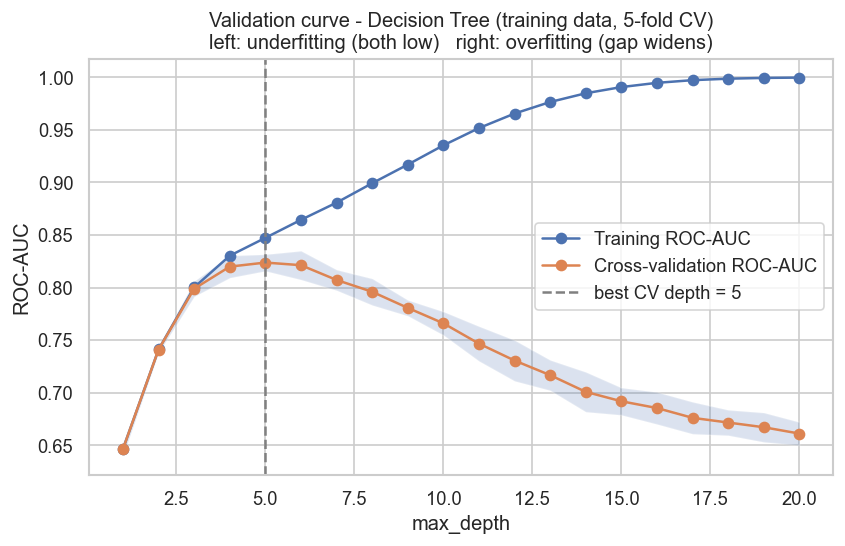

,max_depth,train_roc_auc,cv_roc_auc
0,1,0.6464,0.6464
1,2,0.7411,0.7410
2,3,0.8002,0.7989
3,4,0.8303,0.8199
4,5,0.8473,0.8238
5,6,0.8644,0.8213
6,7,0.8808,0.8073
7,8,0.8992,0.7960
8,9,0.9169,0.7807
9,10,0.9352,0.7660


In [9]:
display(Image(str(config.FIGURES_DIR / "model_validation_curve_tree_depth.png")))
pd.read_csv(config.REPORTS_DIR / "validation_curve_tree_depth.csv").round(4).head(12)

- **Underfitting** (depth 1-3): training and CV scores are both low - the model is too simple.
- **Good fit** (depth ≈ 5): CV score peaks.
- **Overfitting** (depth > 6): training score keeps rising towards 1.0 while CV score falls - the tree memorises noise.

## Model selection and final test-set evaluation

In [10]:
selected = tuned_cv.sort_values("cv_roc_auc_mean", ascending=False).iloc[0]
print("Selected by highest CV ROC-AUC:", selected["model"], round(selected["cv_roc_auc_mean"], 4))
print("Runner-up:", tuned_cv.sort_values("cv_roc_auc_mean", ascending=False).iloc[1][["model", "cv_roc_auc_mean"]].to_dict())

Selected by highest CV ROC-AUC: Random Forest 0.8476
Runner-up: {'model': 'Logistic Regression', 'cv_roc_auc_mean': 0.8461911076749825}


The full pipeline below (`run_training`) repeats these steps, evaluates **every** model once on the held-out
test set for reporting, and saves the selected pipeline to `models/churn_model.joblib`. With fixed seeds the
results are identical to the step-by-step cells above.

In [11]:
from src.train_model import run_training
from src.evaluate_model import generate_evaluation_artifacts
results = run_training(verbose=False)
generate_evaluation_artifacts(results)
comp = results["comparison"]
comp[["model", "stage", "cv_roc_auc_mean", "test_accuracy", "test_precision", "test_recall",
      "test_f1", "test_roc_auc", "selected"]].round(4)

  tuned Logistic Regression  CV ROC-AUC=0.8462  (2.9 s)


  tuned Decision Tree        CV ROC-AUC=0.8339  (6.7 s)


  tuned Random Forest        CV ROC-AUC=0.8476  (37.1 s)


  tuned LDA                  CV ROC-AUC=0.8440  (0.8 s)


,model,stage,cv_roc_auc_mean,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc,selected
0,Majority-class baseline,baseline,0.5000,0.7346,0.0000,0.0000,0.0000,0.5000,False
1,Logistic Regression,baseline,0.8459,0.7402,0.5069,0.7861,0.6164,0.8419,False
2,Decision Tree,baseline,0.6611,0.7346,0.5000,0.4813,0.4905,0.6544,False
3,Random Forest,baseline,0.8275,0.7850,0.6195,0.4920,0.5484,0.8262,False
4,LDA,baseline,0.8390,0.7480,0.5176,0.7460,0.6112,0.8297,False
5,Logistic Regression,tuned,0.8462,0.7381,0.5043,0.7807,0.6128,0.8404,False
6,Decision Tree,tuned,0.8339,0.7495,0.5183,0.7968,0.6280,0.8358,False
7,Random Forest,tuned,0.8476,0.7537,0.5240,0.7888,0.6297,0.8454,True
8,LDA,tuned,0.8440,0.7395,0.5060,0.7914,0.6173,0.8356,False


**Interpretation**
- All tuned models land at test ROC-AUC ≈ 0.84-0.85 and F1 ≈ 0.61-0.63. The differences between them are small
  and within CV noise, so the choice of Random Forest is **not** a decisive win over Logistic Regression.
- Recall ≈ 0.79: about 4 in 5 actual churners are flagged. Precision ≈ 0.52: about half of flagged customers
  would actually churn. This trade-off is the result of class weighting, which favours catching churners.
- The test scores are close to the CV scores, which suggests the CV estimate was not over-optimistic.

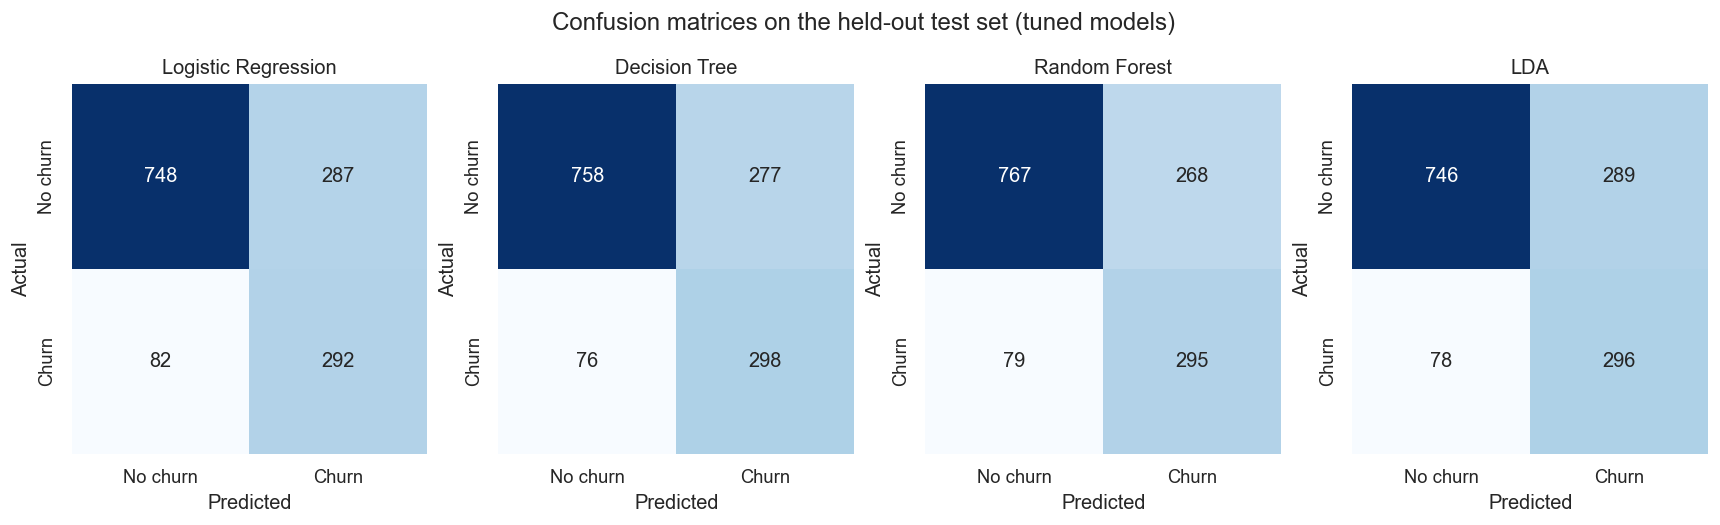

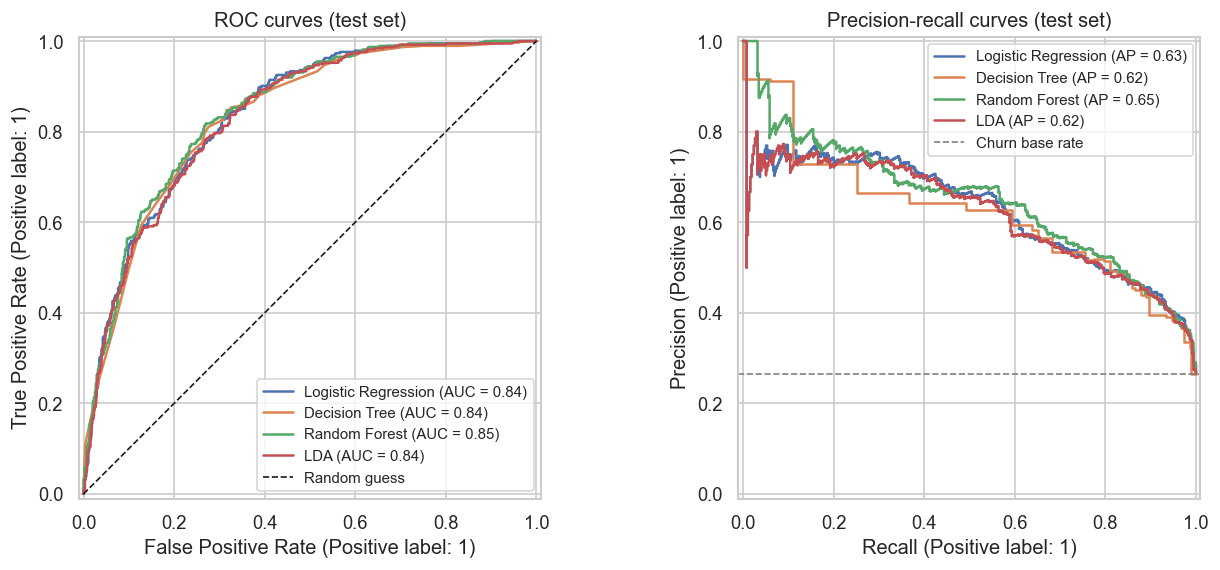

In [12]:
display(Image(str(config.FIGURES_DIR / "model_confusion_matrices_tuned.png")))
display(Image(str(config.FIGURES_DIR / "model_roc_pr_curves.png")))

### Metric definitions (churn = positive class)
- **Accuracy** = (TP + TN) / all
- **Precision** = TP / (TP + FP) - of customers flagged as churners, how many really churned
- **Recall** = TP / (TP + FN) - of real churners, how many we caught
- **F1** = harmonic mean of precision and recall
- **ROC-AUC** = probability that a random churner gets a higher score than a random non-churner (0.5 = random)

For retention, a **false negative** (missed churner) usually costs more than a **false positive** (an
unnecessary retention offer), which is why recall is emphasised.

## Logistic Regression: coefficients and odds ratios

In [13]:
odds = pd.read_csv(config.ODDS_RATIOS_PATH)
odds.round(3)

,feature,coefficient,odds_ratio,unit
0,InternetService_No,-2.814,0.060,vs reference
1,InternetService_Fiber optic,2.755,15.718,vs reference
2,MonthlyCharges,-2.401,0.091,+1 SD (30.1)
3,Contract_Two year,-1.450,0.234,vs reference
4,tenure,-1.191,0.304,+1 SD (24.6)
5,PhoneService_Yes,1.056,2.874,vs reference
6,StreamingMovies_Yes,1.033,2.811,vs reference
7,StreamingTV_Yes,1.008,2.741,vs reference
8,Contract_One year,-0.730,0.482,vs reference
9,MultipleLines_Yes,0.632,1.882,vs reference


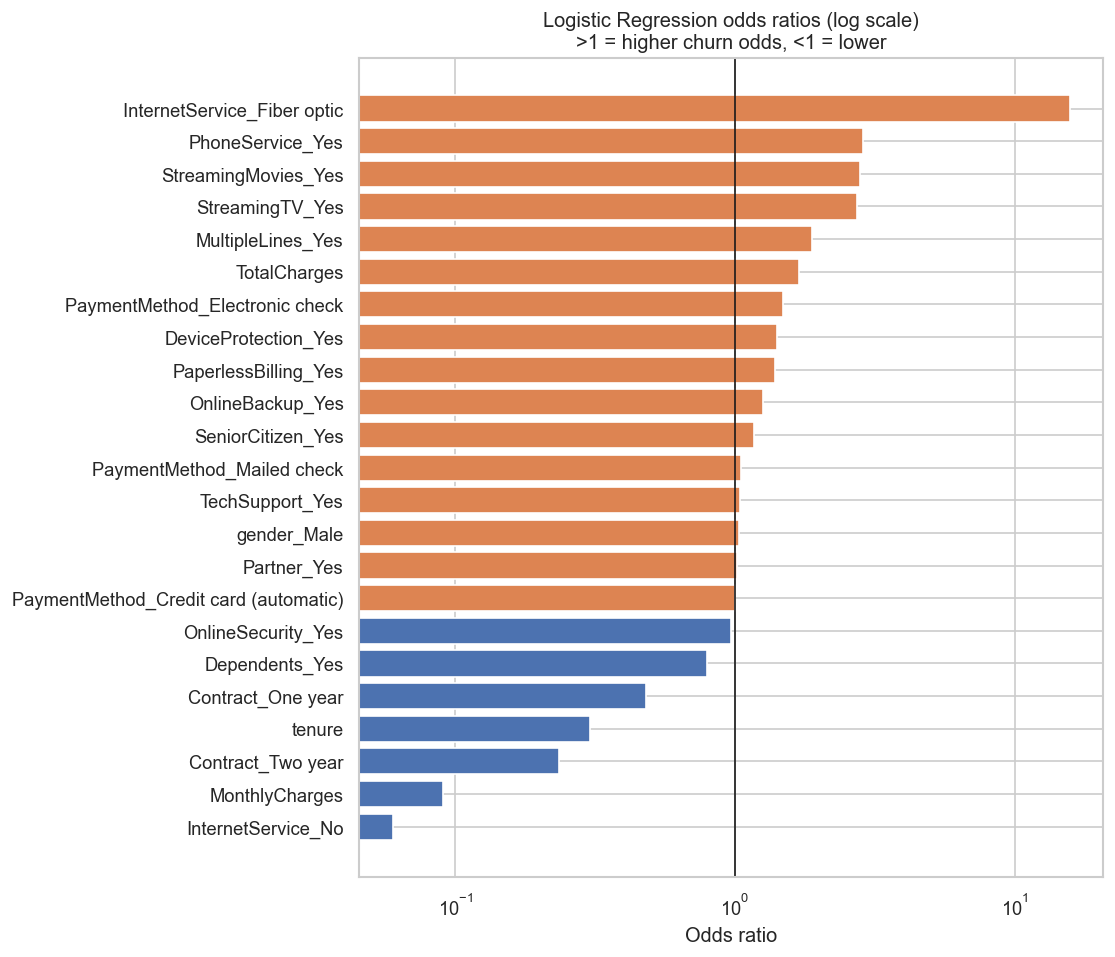

In [14]:
display(Image(str(config.FIGURES_DIR / "model_logistic_odds_ratios.png")))

**How to read an odds ratio (OR):** OR = e^coefficient. OR = 2 means the *odds* of churn are doubled
compared with the reference category, **holding all other features constant**. OR = 0.5 halves the odds.
For numeric features the unit is **one standard deviation** (because features were standardised).

Examples from this model:
- `Contract_Two year` OR ≈ 0.23 → a two-year contract customer has about 77 % lower odds of churn than a
  month-to-month customer with otherwise identical attributes.
- `tenure` OR ≈ 0.30 per +1 SD (≈ 24.6 months) → longer-tenure customers have much lower churn odds.
- `PaymentMethod_Electronic check` OR ≈ 1.49 → about 49 % higher odds than bank transfer (reference).

**Important caution - multicollinearity:** `MonthlyCharges` is almost completely determined by which services a
customer has (a linear regression of MonthlyCharges on the service columns gives R² ≈ 0.999). So the model
can trade weight between `MonthlyCharges` (OR ≈ 0.09) and the service columns (Fiber OR ≈ 15.7, streaming
OR ≈ 2.7). These individual numbers are **not** separately meaningful - in combination, a fiber customer's
higher bill and fiber flag together still raise churn odds. Interpret this group jointly.

In [15]:
from src.data_preprocessing import load_clean_data
from sklearn.linear_model import LinearRegression
services = ["PhoneService", "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
S = pd.get_dummies(df[services], drop_first=True)
print("R² of MonthlyCharges ~ services:", round(LinearRegression().fit(S, df["MonthlyCharges"]).score(S, df["MonthlyCharges"]), 4))

R² of MonthlyCharges ~ services: 0.9988


## Feature importance of the selected model

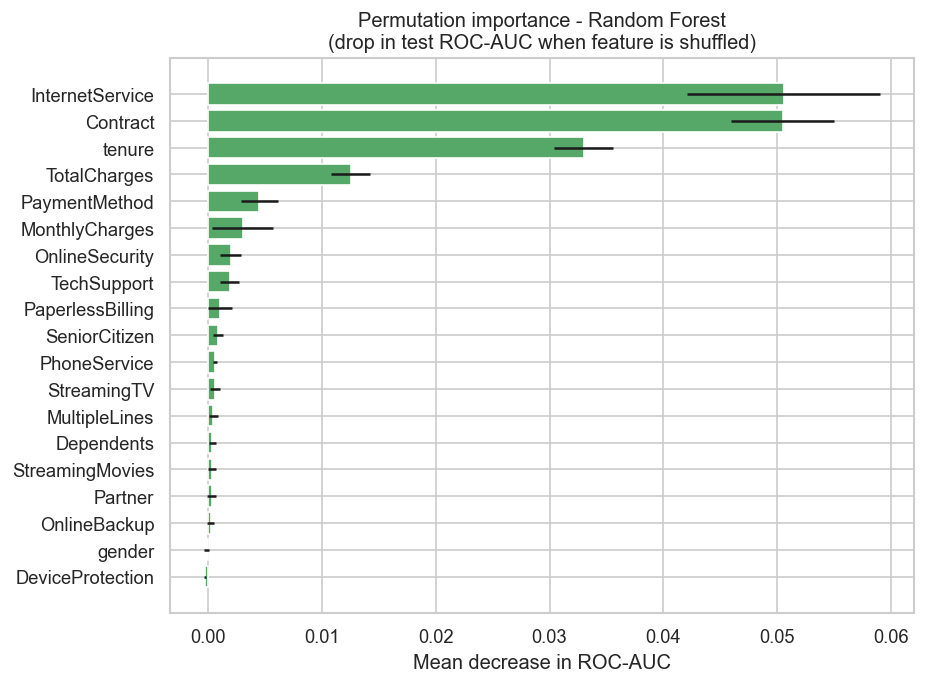

,feature,importance_mean,importance_std
0,InternetService,0.0506,0.0085
1,Contract,0.0505,0.0045
2,tenure,0.0330,0.0026
3,TotalCharges,0.0125,0.0017
4,PaymentMethod,0.0045,0.0017
5,MonthlyCharges,0.0030,0.0027
6,OnlineSecurity,0.0020,0.0009
7,TechSupport,0.0019,0.0009


In [16]:
display(Image(str(config.FIGURES_DIR / "model_permutation_importance.png")))
pd.read_csv(config.FEATURE_IMPORTANCE_PATH).round(4).head(8)

Permutation importance shuffles one raw feature at a time and measures the drop in test ROC-AUC.
`InternetService`, `Contract` and `tenure` matter most - consistent with the EDA findings.

## Saved model check

In [17]:
from src.predict import predict_customers, EXAMPLE_CUSTOMER
print(EXAMPLE_CUSTOMER)
predict_customers(EXAMPLE_CUSTOMER)

{'gender': 'Female', 'SeniorCitizen': 'No', 'Partner': 'No', 'Dependents': 'No', 'tenure': 3, 'PhoneService': 'Yes', 'MultipleLines': 'No', 'InternetService': 'Fiber optic', 'OnlineSecurity': 'No', 'OnlineBackup': 'No', 'DeviceProtection': 'No', 'TechSupport': 'No', 'StreamingTV': 'Yes', 'StreamingMovies': 'No', 'Contract': 'Month-to-month', 'PaperlessBilling': 'Yes', 'PaymentMethod': 'Electronic check', 'MonthlyCharges': 85.0, 'TotalCharges': 255.0}


,churn_probability,prediction
0,0.845106,Churn


## G. Retention analysis summary
Data-driven findings (associations only):
- Month-to-month contracts, tenure under 12 months, fiber-optic internet, electronic-check payment and absence of
  online security / tech support are associated with markedly higher churn.
- The models confirm the same drivers (permutation importance, odds ratios).

Suggested (untested) actions: early-tenure onboarding, contract-upgrade incentives, a review of the fiber-optic
experience, add-on bundles, auto-pay nudges, and risk-ranked outreach using the model's probabilities.
Each should be validated with a controlled experiment, because the data cannot show **cause**.
See `reports/project_report.md` and the dashboard's *Retention Recommendations* page.